In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVR, SVC
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import r2_score, mean_absolute_error, accuracy_score

In [2]:
df = pd.read_csv("insurance.csv")

print(df.head())
print("Dataset shape:", df.shape)
print(df.info())

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
Dataset shape: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None


In [3]:
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicate rows: 1


               age          bmi     children       charges
count  1337.000000  1337.000000  1337.000000   1337.000000
mean     39.222139    30.663452     1.095737  13279.121487
std      14.044333     6.100468     1.205571  12110.359656
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.290000     0.000000   4746.344000
50%      39.000000    30.400000     1.000000   9386.161300
75%      51.000000    34.700000     2.000000  16657.717450
max      64.000000    53.130000     5.000000  63770.428010


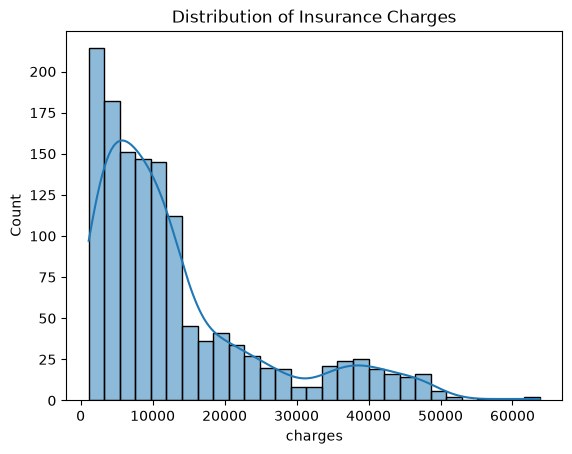

In [4]:
print(df.describe())

sns.histplot(df["charges"], kde=True)
plt.title("Distribution of Insurance Charges")
plt.show()

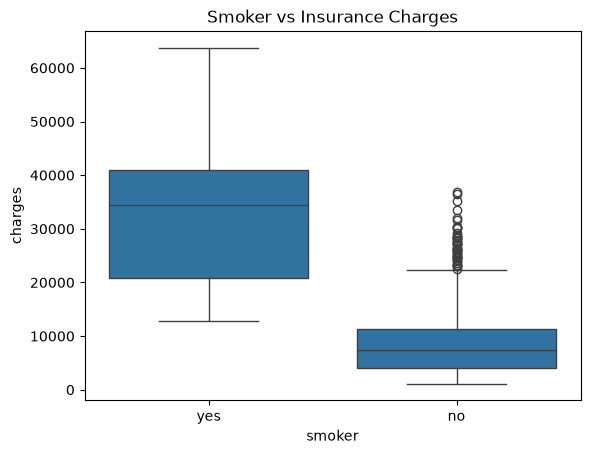

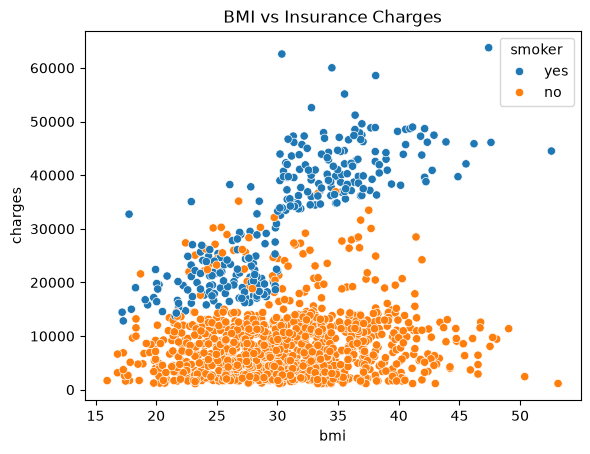

In [5]:
sns.boxplot(data=df, x="smoker", y="charges")
plt.title("Smoker vs Insurance Charges")
plt.show()

sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker")
plt.title("BMI vs Insurance Charges")
plt.show()

In [6]:
X = df.drop("charges", axis=1)
y = df["charges"]

numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

# Scale numerical data and encode categorical data
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 1069
Testing rows: 268


In [8]:
lr = make_pipeline(preprocessor, LinearRegression())

lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

print("R2 Score:", round(r2_score(y_test, pred_lr), 3))
print("MAE:", round(mean_absolute_error(y_test, pred_lr), 2))

R2 Score: 0.807
MAE: 4177.05


### Polynomial Regression

In [9]:
poly = make_pipeline(
    preprocessor,
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly.fit(X_train, y_train)
pred_poly = poly.predict(X_test)

print("Polynomial R2:", round(r2_score(y_test, pred_poly), 3))
print("Polynomial MAE:", round(mean_absolute_error(y_test, pred_poly), 2))

Polynomial R2: 0.883
Polynomial MAE: 2867.32


### KNN Regressor

In [10]:
knn = make_pipeline(
    preprocessor,
    KNeighborsRegressor(n_neighbors=5)
)

knn.fit(X_train, y_train)
pred_knn = knn.predict(X_test)

print("KNN R2:", round(r2_score(y_test, pred_knn), 3))
print("KNN MAE:", round(mean_absolute_error(y_test, pred_knn), 2))

KNN R2: 0.782
KNN MAE: 3806.58


### SVM

In [11]:
svm = make_pipeline(preprocessor, SVR())

svm.fit(X_train, y_train)
pred_svm = svm.predict(X_test)

print("SVM R2:", round(r2_score(y_test, pred_svm), 3))
print("SVM MAE:", round(mean_absolute_error(y_test, pred_svm), 2))

SVM R2: -0.132
SVM MAE: 9260.28


                   Model  R2 Score
1  Polynomial Regression  0.882530
0      Linear Regression  0.806929
2         KNN Regression  0.781590
3         SVM Regression -0.132427


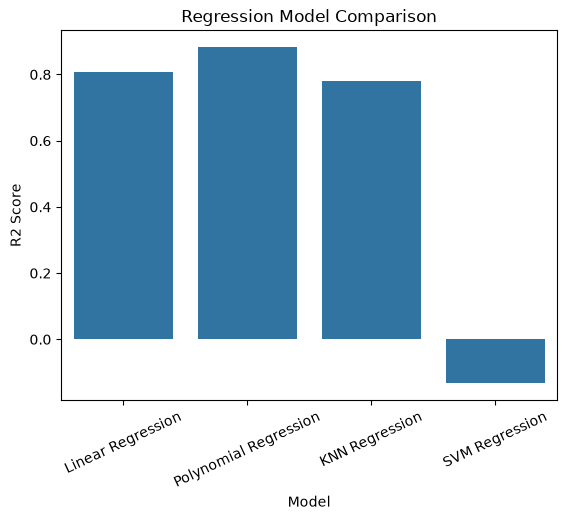

In [12]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression",
              "KNN Regression", "SVM Regression"],
    "R2 Score": [
        r2_score(y_test, pred_lr),
        r2_score(y_test, pred_poly),
        r2_score(y_test, pred_knn),
        r2_score(y_test, pred_svm)
    ]
})

print(results.sort_values("R2 Score", ascending=False))

sns.barplot(data=results, x="Model", y="R2 Score")
plt.xticks(rotation=25)
plt.title("Regression Model Comparison")
plt.show()

In [13]:
# Classify insurance charges as high or normal
threshold = y_train.median()

y_train_class = (y_train > threshold).astype(int)
y_test_class = (y_test > threshold).astype(int)

log_model = make_pipeline(
    preprocessor, LogisticRegression(max_iter=1000)
)

log_model.fit(X_train, y_train_class)
pred_class = log_model.predict(X_test)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test_class, pred_class), 3))

Logistic Regression Accuracy: 0.918


In [14]:
for name, classifier in [
    ("KNN Classifier", KNeighborsClassifier(n_neighbors=5)),
    ("SVM Classifier", SVC())
]:
    model = make_pipeline(preprocessor, classifier)
    model.fit(X_train, y_train_class)

    prediction = model.predict(X_test)

    print(name, "Accuracy:",
          round(accuracy_score(y_test_class, prediction), 3))

KNN Classifier Accuracy: 0.903
SVM Classifier Accuracy: 0.94


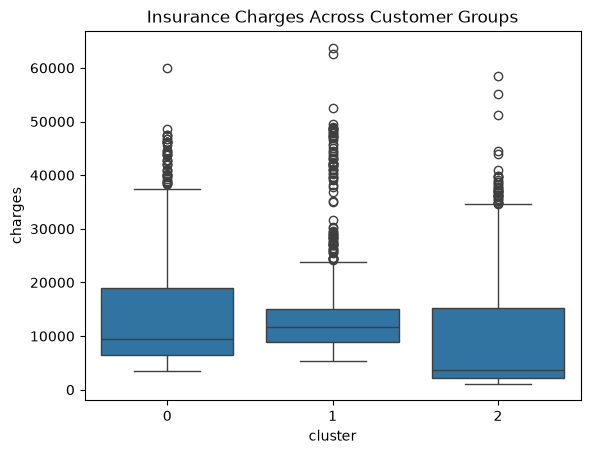

Best Model: Polynomial Regression
Predicted Insurance Cost: 5813.93


In [15]:
# Group customers by their insurance-related features
X_cluster = preprocessor.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_cluster)

sns.boxplot(data=df, x="cluster", y="charges")
plt.title("Insurance Charges Across Customer Groups")
plt.show()

# Predict charges for a new customer using the best model
best_model = max(
    [("Linear Regression", lr), ("Polynomial Regression", poly),
     ("KNN Regression", knn), ("SVM Regression", svm)],
    key=lambda item: r2_score(
        y_test,
        item[1].predict(X_test)
    )
)

new_person = pd.DataFrame([{
    "age": 30,
    "sex": "male",
    "bmi": 28.5,
    "children": 1,
    "smoker": "no",
    "region": "southeast"
}])

print("Best Model:", best_model[0])
print("Predicted Insurance Cost:",
      round(best_model[1].predict(new_person)[0], 2))